In [1]:
%pip install pandas seaborn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import glob
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 16})
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["lines.linewidth"] = 1

In [3]:
serial_df = pd.read_csv('../serial/results.csv')
omp_df = pd.read_csv('../openmp/results.csv')
mpi_df = pd.read_csv('../mpi/results.csv')
cuda_df = pd.read_csv('../cuda/results.csv')
addn_df = pd.read_csv('../additional/results.csv')

In [4]:
serial_col = "#000000"
omp_col = sns.color_palette("Blues", 6)
mpi_col = sns.color_palette("Reds", 6)
cuda_col = sns.color_palette("Greens", 6)
addn_col = sns.color_palette("Oranges", 6)

In [5]:
ns = np.array(sorted(serial_df["n"].unique()))

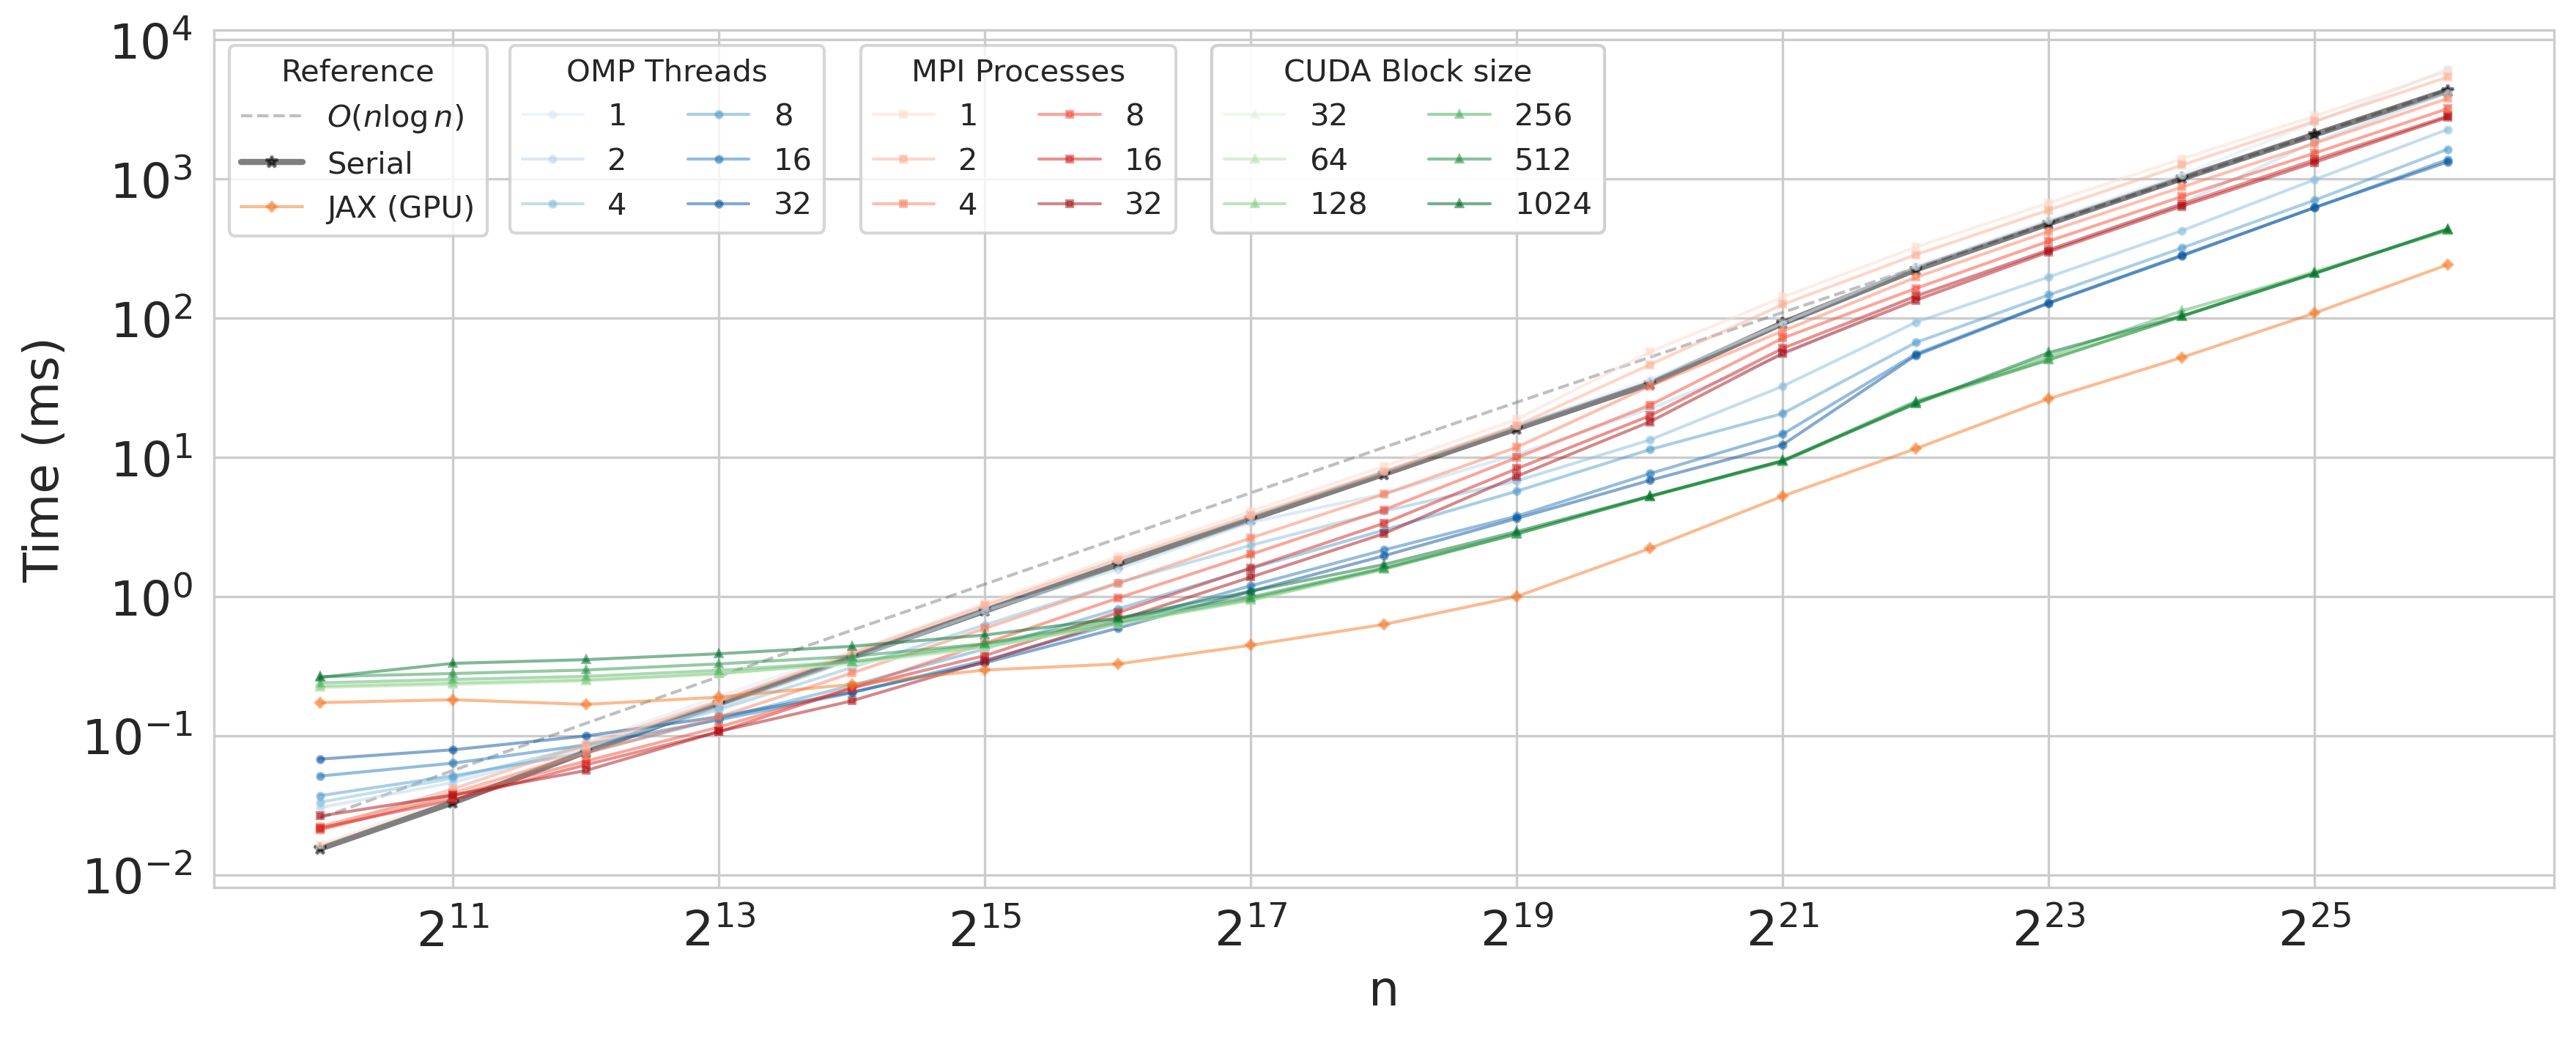

In [6]:
fig, ax = plt.subplots()

# --- plot each group ---
# reference
l_ref = ax.plot(
    ns,
    ns * np.log2(ns) * 2.5e-6,
    color="gray",
    linestyle="--",
    alpha=0.5,
    label="$O(n \\log n)$",
)[0]
l_serial = ax.plot(
    serial_df["n"],
    serial_df["time_ms"],
    color=serial_col,
    linewidth=2,
    alpha=0.5,
    marker="*",
    markersize=4,
    label="Serial",
)[0]

# openmp
omp_handles = []
for i, t in enumerate(sorted(omp_df["threads"].unique())):
    sub = omp_df[omp_df["threads"] == t]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=omp_col[i],
        alpha=0.5,
        marker="o",
        markersize=2,
    )
    omp_handles.append(h)

# mpi
mpi_handles = []
for i, p in enumerate(sorted(mpi_df["processes"].unique())):
    sub = mpi_df[mpi_df["processes"] == p]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=mpi_col[i],
        alpha=0.5,
        marker="s",
        markersize=2,
    )
    mpi_handles.append(h)

# cuda
cuda_handles = []
for i, bs in enumerate(sorted(cuda_df["block_size"].unique())):
    sub = cuda_df[cuda_df["block_size"] == bs]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=cuda_col[i],
        alpha=0.5,
        marker="^",
        markersize=2,
    )
    cuda_handles.append(h)

# jax
l_jax = ax.plot(
    addn_df["n"],
    addn_df["time_ms"],
    color=addn_col[3],
    label="JAX (GPU)",
    alpha=0.5,
    marker="D",
    markersize=2,
)[0]

ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("n")
ax.set_ylabel("Time (ms)")

# --- separate legends ---
fs = 10

# reference + jax (top left)
leg1 = ax.legend(
    handles=[l_ref, l_serial, l_jax],
    fontsize=fs,
    loc="upper left",
    title="Reference",
    title_fontsize=fs,
)
ax.add_artist(leg1)

# openmp
leg2_labels = [str(t) for t in sorted(omp_df["threads"].unique())]
leg2 = ax.legend(
    handles=omp_handles,
    labels=leg2_labels,
    fontsize=fs,
    bbox_to_anchor=(0.12, 1.0),
    loc="upper left",
    title="OMP Threads",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg2)

# mpi
leg3_labels = [str(p) for p in sorted(mpi_df["processes"].unique())]
leg3 = ax.legend(
    handles=mpi_handles,
    labels=leg3_labels,
    fontsize=fs,
    bbox_to_anchor=(0.27, 1.0),
    loc="upper left",
    title="MPI Processes",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg3)

# cuda
leg4_labels = [str(bs) for bs in sorted(cuda_df["block_size"].unique())]
leg4 = ax.legend(
    handles=cuda_handles,
    labels=leg4_labels,
    fontsize=fs,
    bbox_to_anchor=(0.42, 1.0),
    loc="upper left",
    title="CUDA Block size",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg4)

plt.tight_layout()
plt.savefig("plots/overview.svg")
plt.show()

# OMP

## Strong scaling

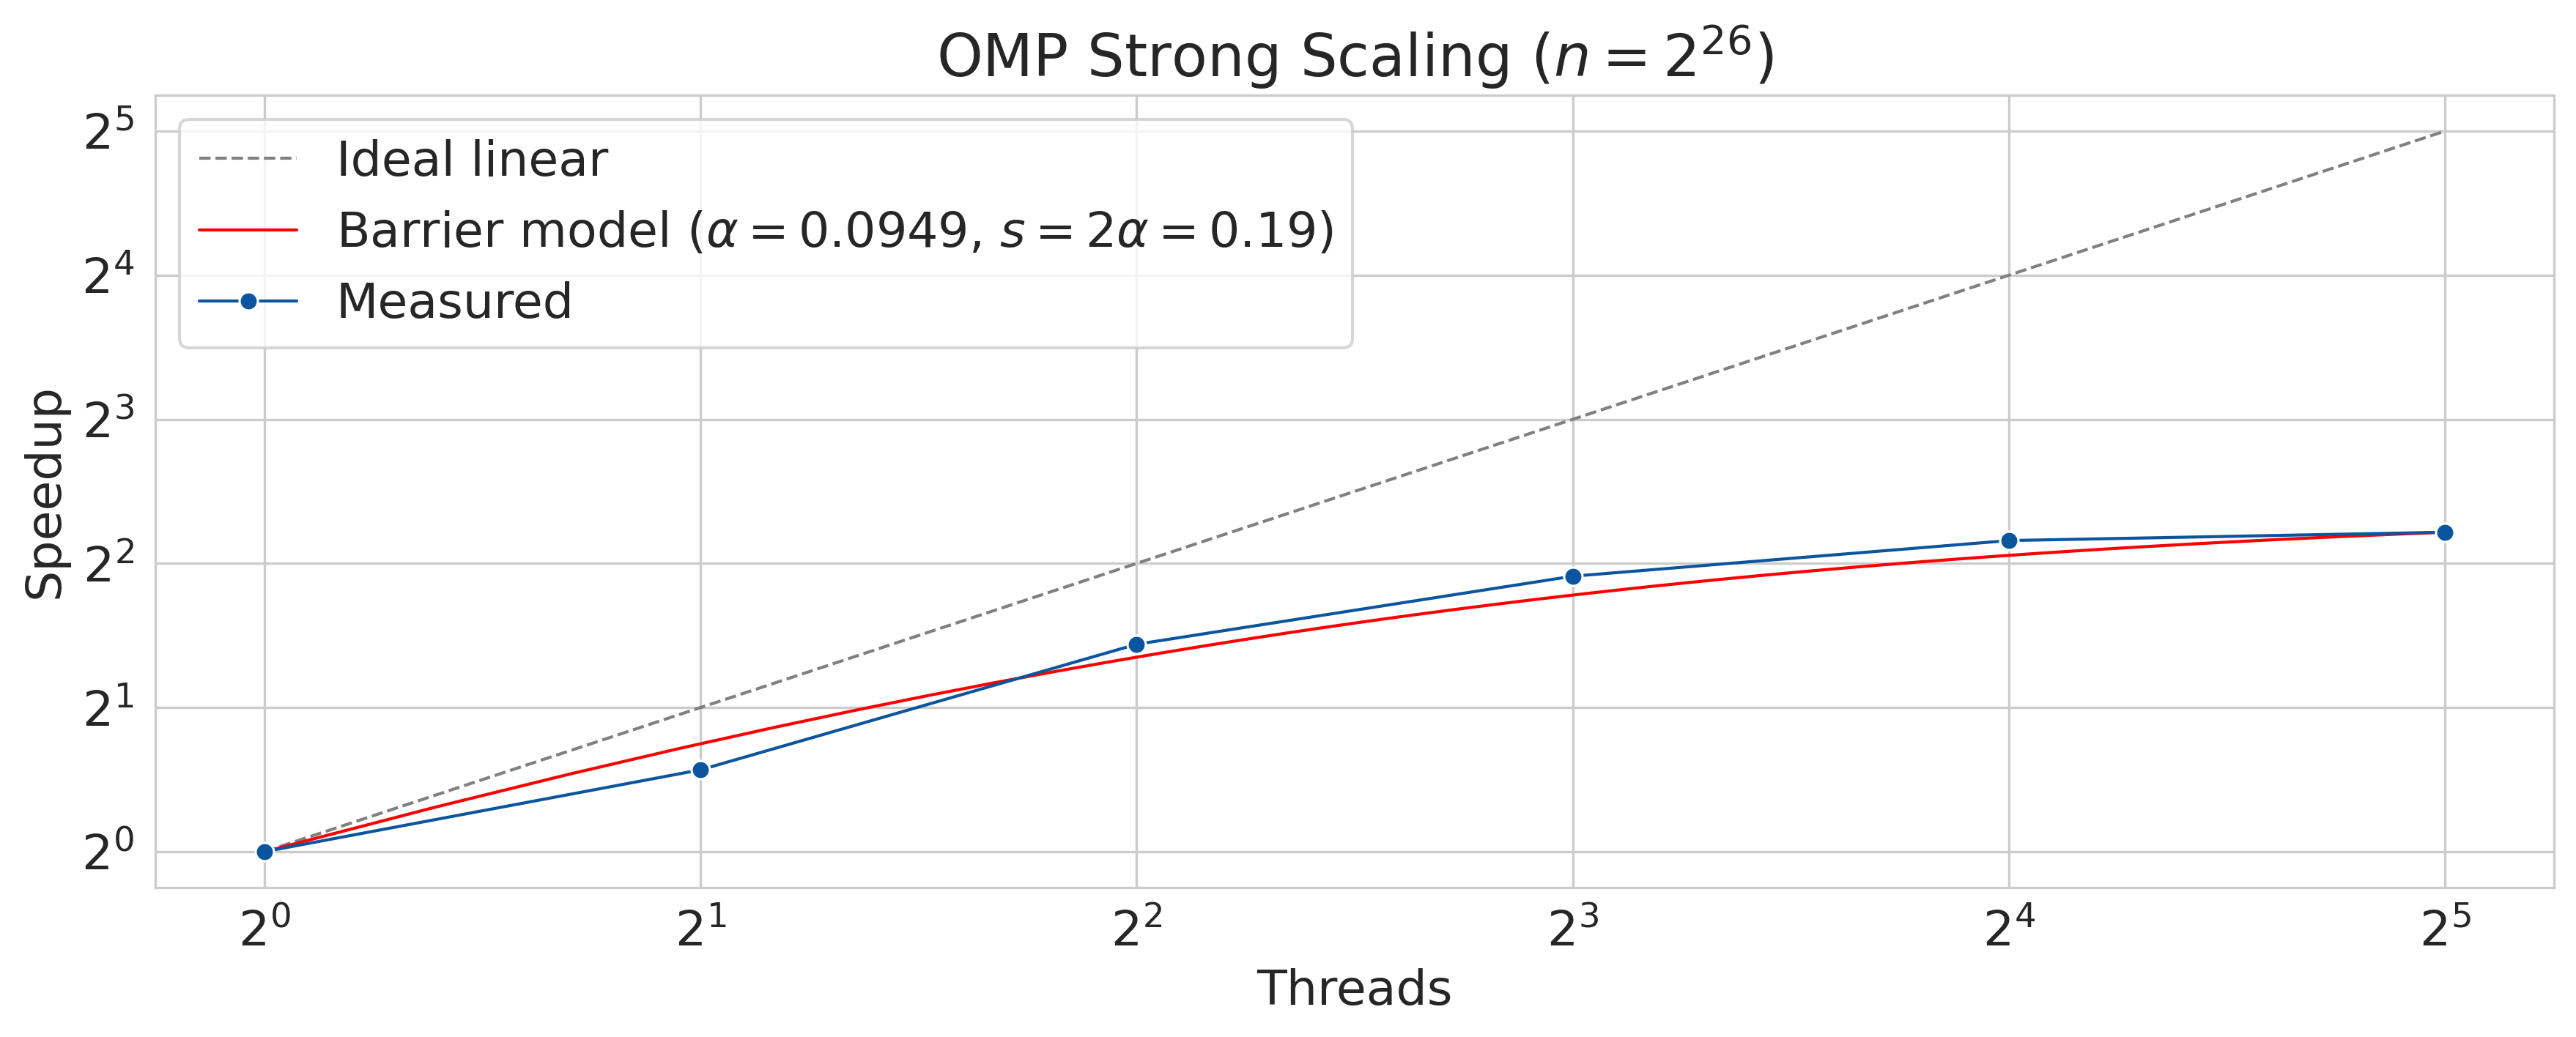

In [48]:
n_to_compare = max(omp_df["n"])
omp_strong_df = omp_df[omp_df["n"] == n_to_compare]
baseline = omp_strong_df[omp_strong_df["threads"] == 1]["time_ms"].values[0]

threads = np.array(sorted(omp_strong_df["threads"].unique()))
speedups = [
    baseline
    / omp_strong_df[omp_strong_df["threads"] == t]["time_ms"].values[0]
    for t in threads
]

# Barrier model: S(p) = p / (1 + 2(p-1) * alpha)
# Equivalent to Amdahl's law for fixed n, with s = 2*alpha
p_max = threads[-1]
alpha_omp = (p_max / speedups[-1] - 1) / (2 * (p_max - 1))
p_smooth = np.linspace(1, p_max, 100)
theoretical = p_smooth / (1 + 2 * (p_smooth - 1) * alpha_omp)

plt.plot(threads, threads, linestyle="--", color="gray", label="Ideal linear")
plt.plot(
    p_smooth,
    theoretical,
    linestyle="-",
    color="red",
    label=f"Barrier model ($\\alpha={alpha_omp:.4f}$, $s=2\\alpha={2*alpha_omp:.2f}$)",
)

sns.lineplot(
    x=threads, y=speedups, marker="o", color=omp_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.yscale("log", base=2)
plt.xlabel("Threads")
plt.ylabel("Speedup")
plt.title(f"OMP Strong Scaling ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.tight_layout()
plt.savefig("plots/omp_strong.svg")
plt.show()

## Weak scaling

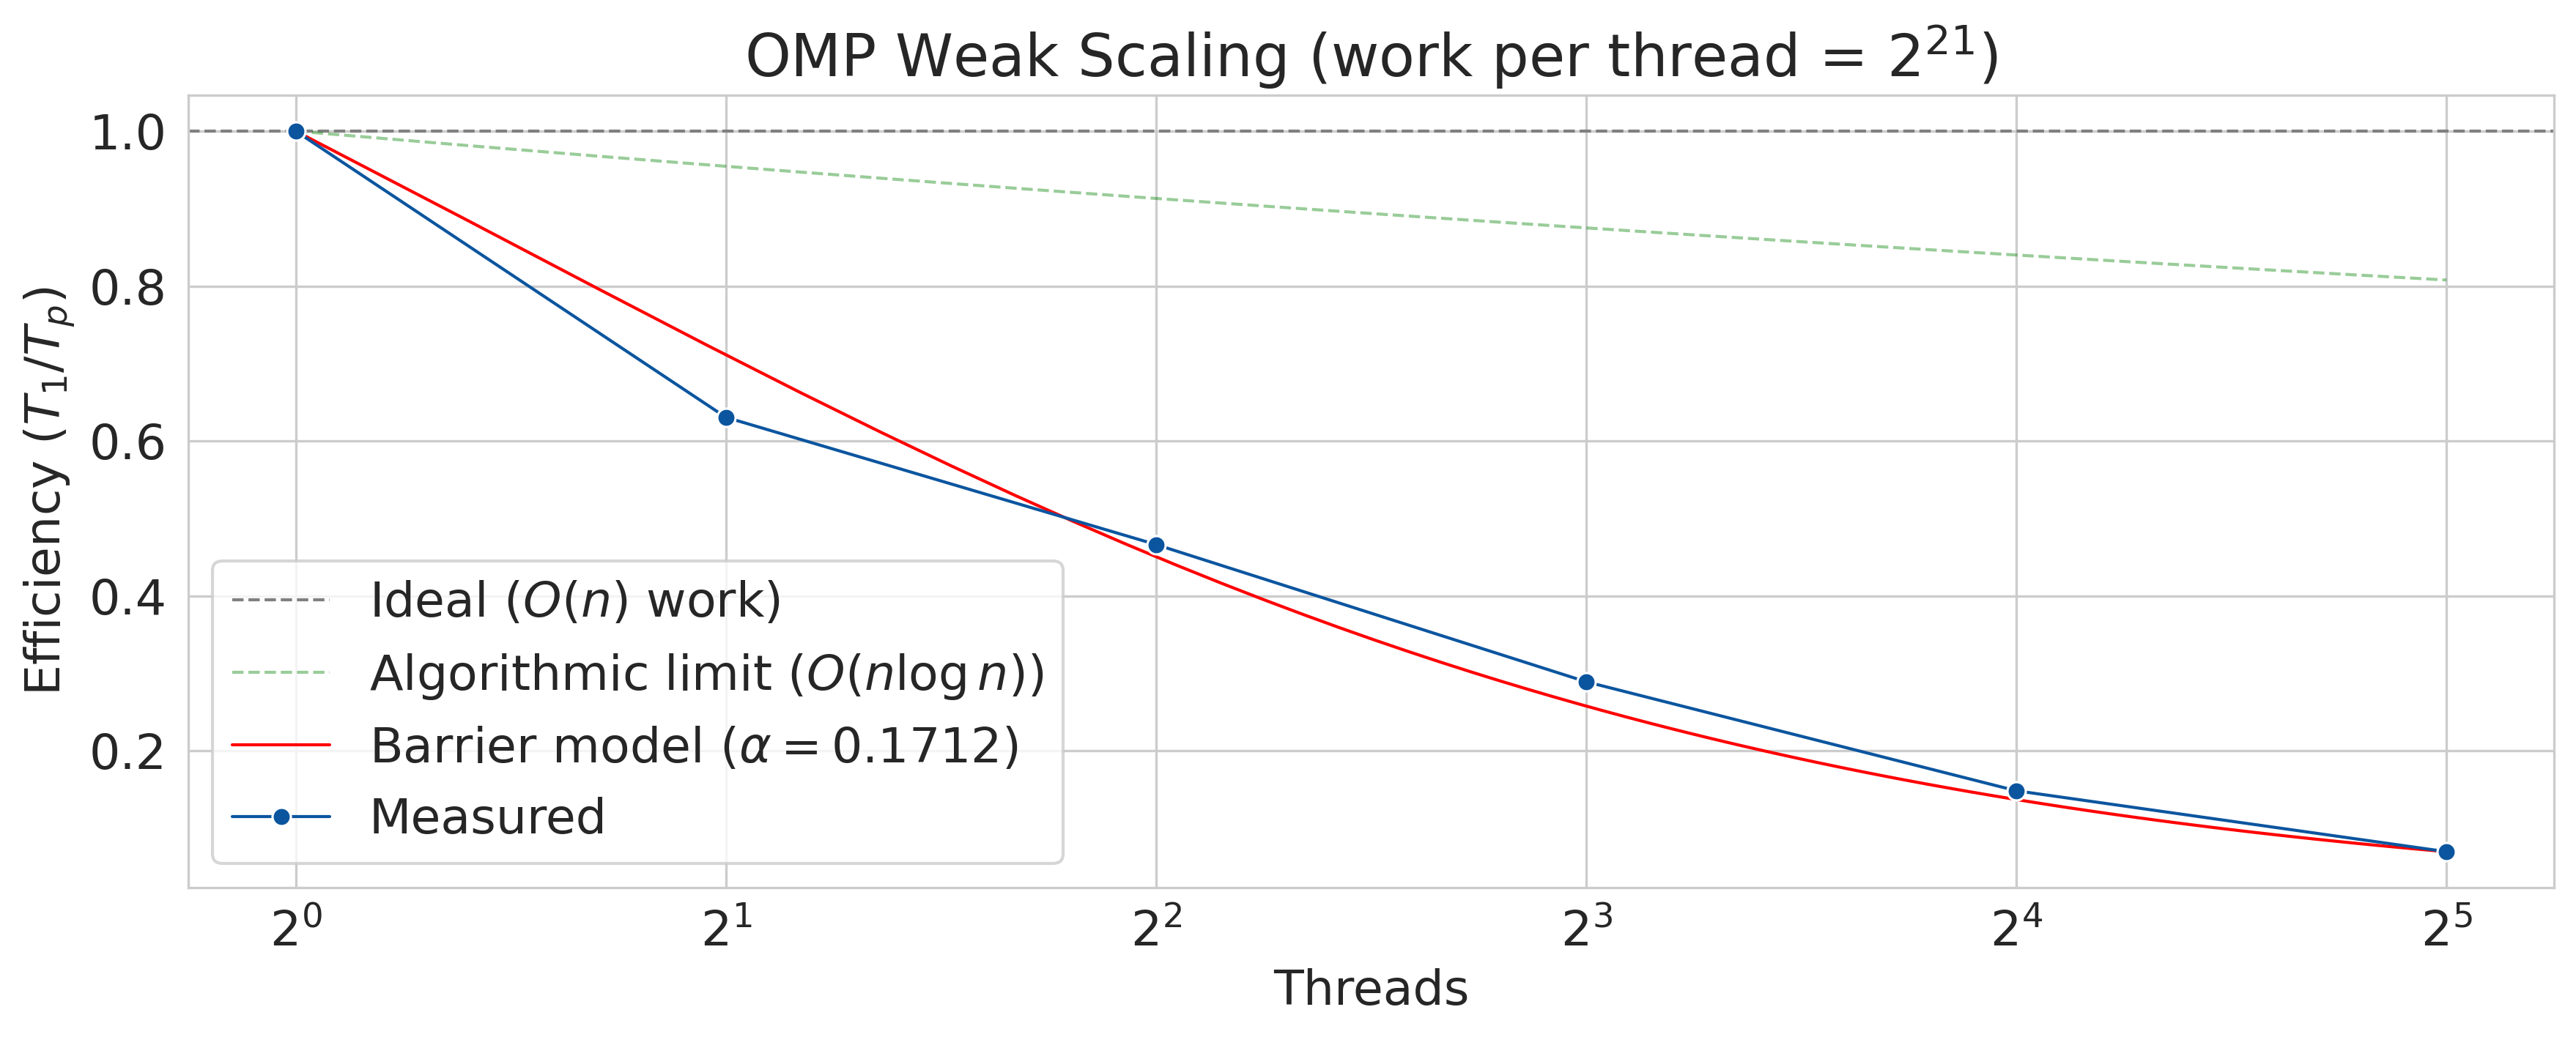

In [40]:
n_per_thread = int(n_to_compare / max(threads))
L = int(np.log2(n_per_thread))
baseline = omp_df[(omp_df["threads"] == 1) & (omp_df["n"] == n_per_thread)][
    "time_ms"
].values[0]

efficiency = [
    baseline
    / omp_df[(omp_df["threads"] == t) & (omp_df["n"] == t * n_per_thread)][
        "time_ms"
    ].values[0]
    for t in threads
]

# Algorithmic limit: E = L / (L + log2(p)), from O(n log n) work growth
p_smooth = np.linspace(1, max(threads), 100)
algorithmic = L / (L + np.log2(p_smooth))

# Barrier model: E(p) = L / [(L + log2(p)) * (1 + 2(p-1) * alpha)]
# Fit alpha from the max-thread measurement
p_max = threads[-1]
E_max = efficiency[-1]
alpha_weak = (L / (E_max * (L + np.log2(p_max))) - 1) / (2 * (p_max - 1))
barrier_model = L / (
    (L + np.log2(p_smooth)) * (1 + 2 * (p_smooth - 1) * alpha_weak)
)

plt.axhline(y=1, linestyle="--", color="gray", label="Ideal ($O(n)$ work)")
plt.plot(
    p_smooth,
    algorithmic,
    linestyle="--",
    color="green",
    alpha=0.4,
    label=f"Algorithmic limit ($O(n \\log n)$)",
)
plt.plot(
    p_smooth,
    barrier_model,
    linestyle="-",
    color="red",
    label=f"Barrier model ($\\alpha={alpha_weak:.4f}$)",
)

sns.lineplot(
    x=threads, y=efficiency, marker="o", color=omp_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.xlabel("Threads")
plt.ylabel("Efficiency ($T_1 / T_p$)")
plt.title(f"OMP Weak Scaling (work per thread = $2^{{{L}}}$)")
plt.legend()
plt.tight_layout()
plt.savefig("plots/omp_weak.svg")
plt.show()

## Speedup vs Serial

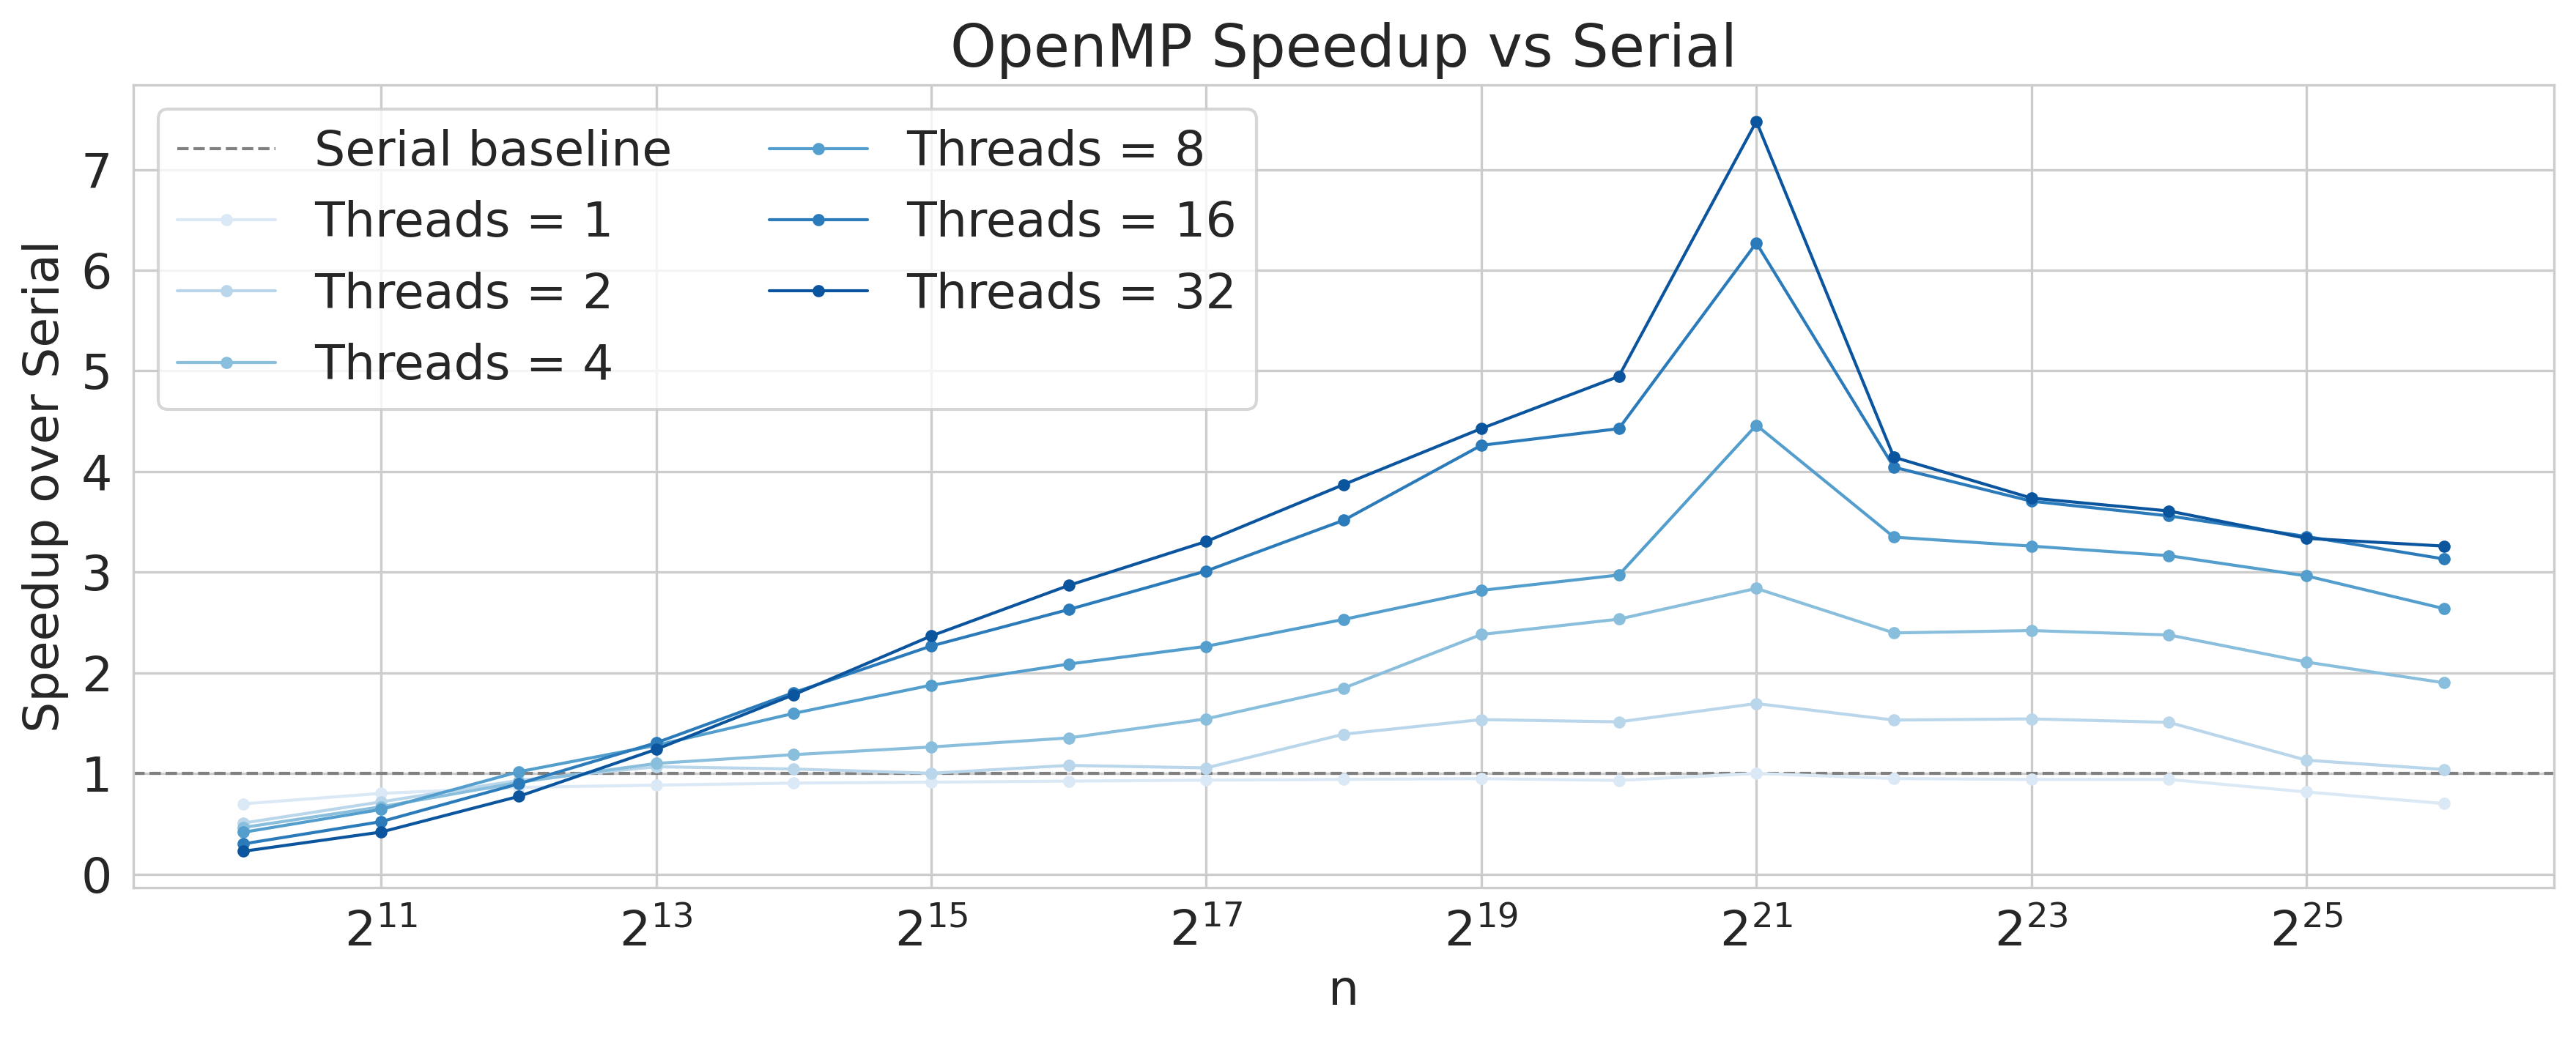

In [43]:
omp_merged = omp_df.merge(serial_df, on="n", suffixes=("_omp", "_serial"))
omp_merged["speedup"] = (
    omp_merged["time_ms_serial"] / omp_merged["time_ms_omp"]
)
plt.axhline(y=1, linestyle="--", color="gray", label="Serial baseline")

thread_counts = sorted(omp_df["threads"].unique())
for i, t in enumerate(thread_counts):
    subset = omp_merged[omp_merged["threads"] == t]
    plt.plot(
        subset["n"],
        subset["speedup"],
        marker="o",
        markersize=3,
        color=omp_col[i],
        label=f"Threads = {t}",
    )

plt.xscale("log", base=2)
plt.xlabel("n")
plt.ylabel("Speedup over Serial")
plt.title("OpenMP Speedup vs Serial")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig("plots/omp_speedup.svg")
plt.show()

# MPI

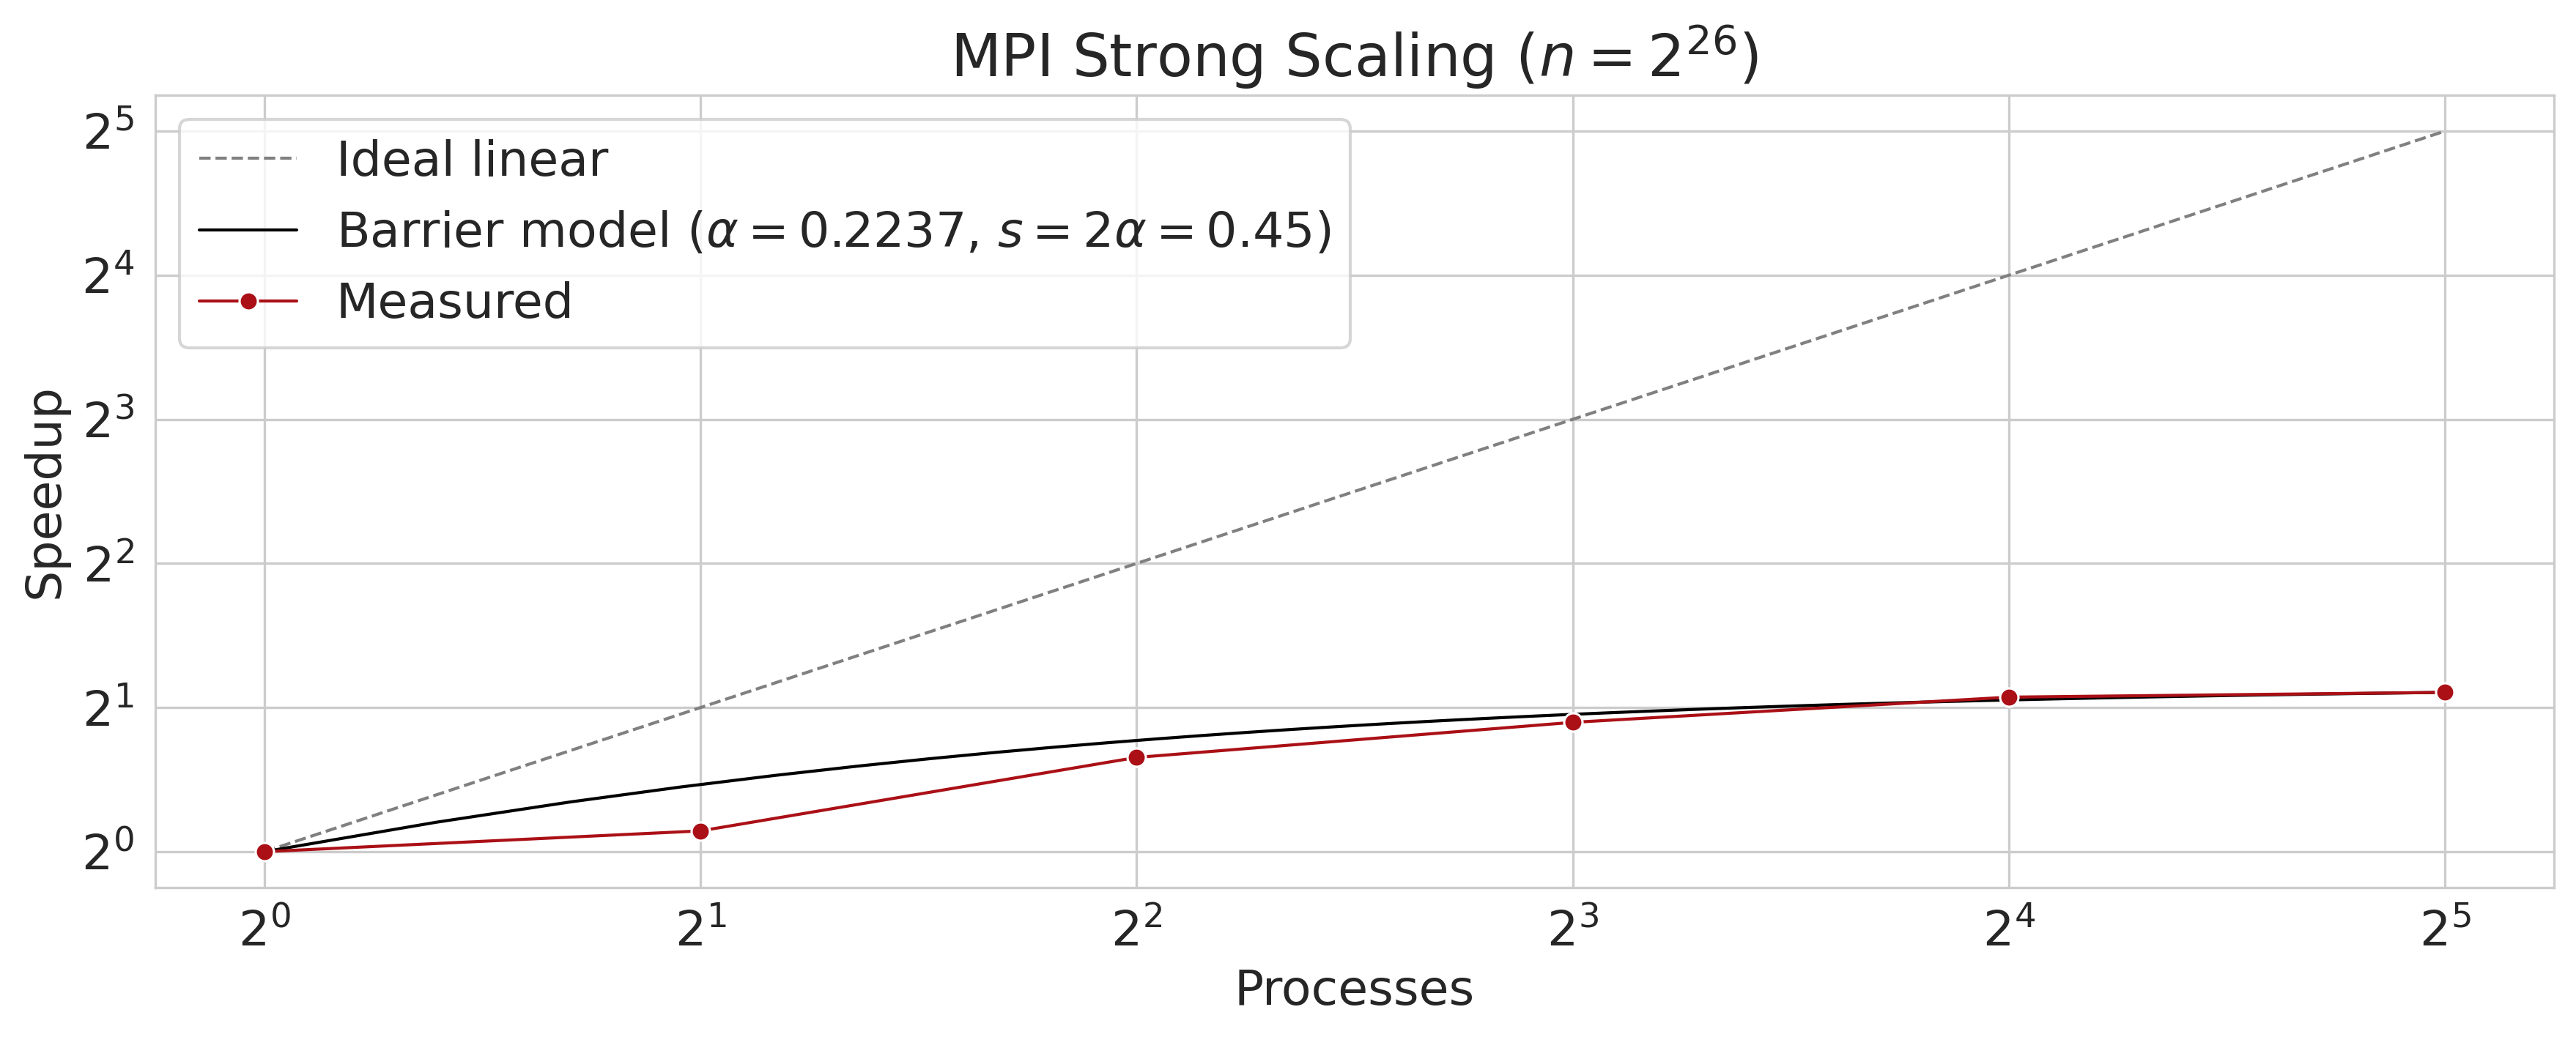

In [47]:
n_to_compare = max(mpi_df["n"])
mpi_strong_df = mpi_df[mpi_df["n"] == n_to_compare]
baseline = mpi_strong_df[mpi_strong_df["processes"] == 1]["time_ms"].values[0]

processes = np.array(sorted(mpi_strong_df["processes"].unique()))
speedups = [
    baseline
    / mpi_strong_df[mpi_strong_df["processes"] == t]["time_ms"].values[0]
    for t in processes
]

# Barrier model: S(p) = p / (1 + 2(p-1) * alpha)
p_max = processes[-1]
alpha_mpi = (p_max / speedups[-1] - 1) / (2 * (p_max - 1))
p_smooth = np.linspace(1, p_max, 100)
theoretical = p_smooth / (1 + 2 * (p_smooth - 1) * alpha_mpi)

plt.plot(
    processes, processes, linestyle="--", color="gray", label="Ideal linear"
)
plt.plot(
    p_smooth,
    theoretical,
    linestyle="-",
    color="black",
    label=f"Barrier model ($\\alpha={alpha_mpi:.4f}$, $s=2\\alpha={2*alpha_mpi:.2f}$)",
)

sns.lineplot(
    x=processes, y=speedups, marker="o", color=mpi_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.yscale("log", base=2)
plt.xlabel("Processes")
plt.ylabel("Speedup")
plt.title(f"MPI Strong Scaling ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.tight_layout()
plt.savefig("plots/mpi_strong.svg")
plt.show()

## Weak scaling

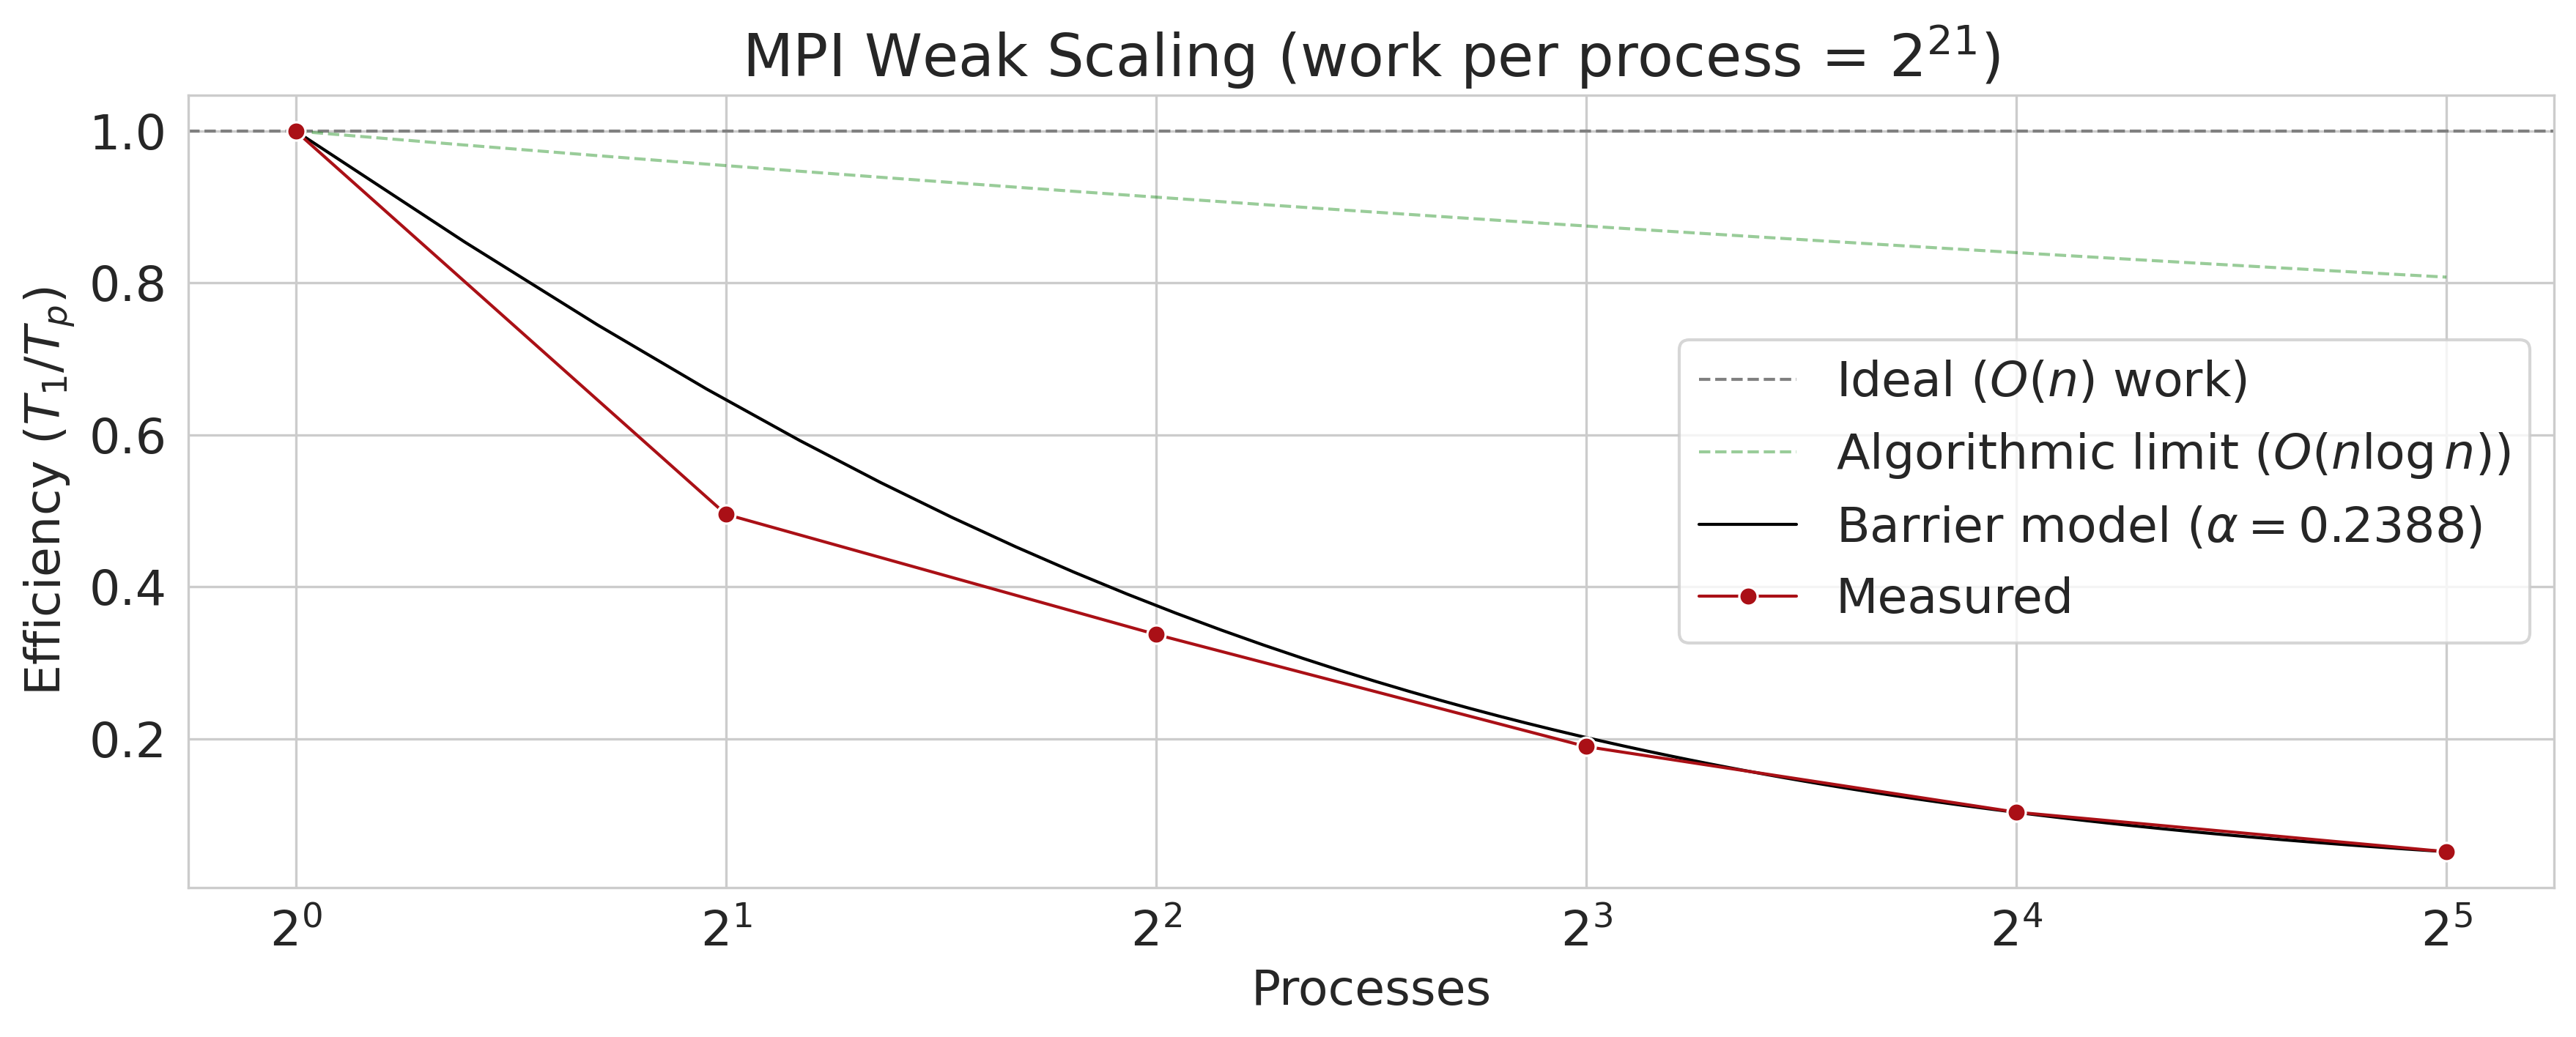

In [53]:
n_per_proc = int(n_to_compare / max(processes))
L = int(np.log2(n_per_proc))
baseline = mpi_df[(mpi_df["processes"] == 1) & (mpi_df["n"] == n_per_proc)][
    "time_ms"
].values[0]

efficiency = [
    baseline
    / mpi_df[(mpi_df["processes"] == p) & (mpi_df["n"] == p * n_per_proc)][
        "time_ms"
    ].values[0]
    for p in processes
]

# Algorithmic limit: E = L / (L + log2(p))
p_smooth = np.linspace(1, max(processes), 100)
algorithmic = L / (L + np.log2(p_smooth))

# Barrier model: E(p) = L / [(L + log2(p)) * (1 + 2(p-1) * alpha)]
p_max = processes[-1]
E_max = efficiency[-1]
alpha_weak_mpi = (L / (E_max * (L + np.log2(p_max))) - 1) / (2 * (p_max - 1))
barrier_model = L / (
    (L + np.log2(p_smooth)) * (1 + 2 * (p_smooth - 1) * alpha_weak_mpi)
)

plt.axhline(y=1, linestyle="--", color="gray", label="Ideal ($O(n)$ work)")
plt.plot(
    p_smooth,
    algorithmic,
    linestyle="--",
    color="green",
    alpha=0.4,
    label=f"Algorithmic limit ($O(n \\log n)$)",
)
plt.plot(
    p_smooth,
    barrier_model,
    linestyle="-",
    color="black",
    label=f"Barrier model ($\\alpha={alpha_weak_mpi:.4f}$)",
)

sns.lineplot(
    x=processes, y=efficiency, marker="o", color=mpi_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.xlabel("Processes")
plt.ylabel("Efficiency ($T_1 / T_p$)")
plt.title(f"MPI Weak Scaling (work per process = $2^{{{L}}}$)")
plt.legend()
plt.tight_layout()
plt.savefig("plots/mpi_weak.svg")
plt.show()

## Speedup vs Serial

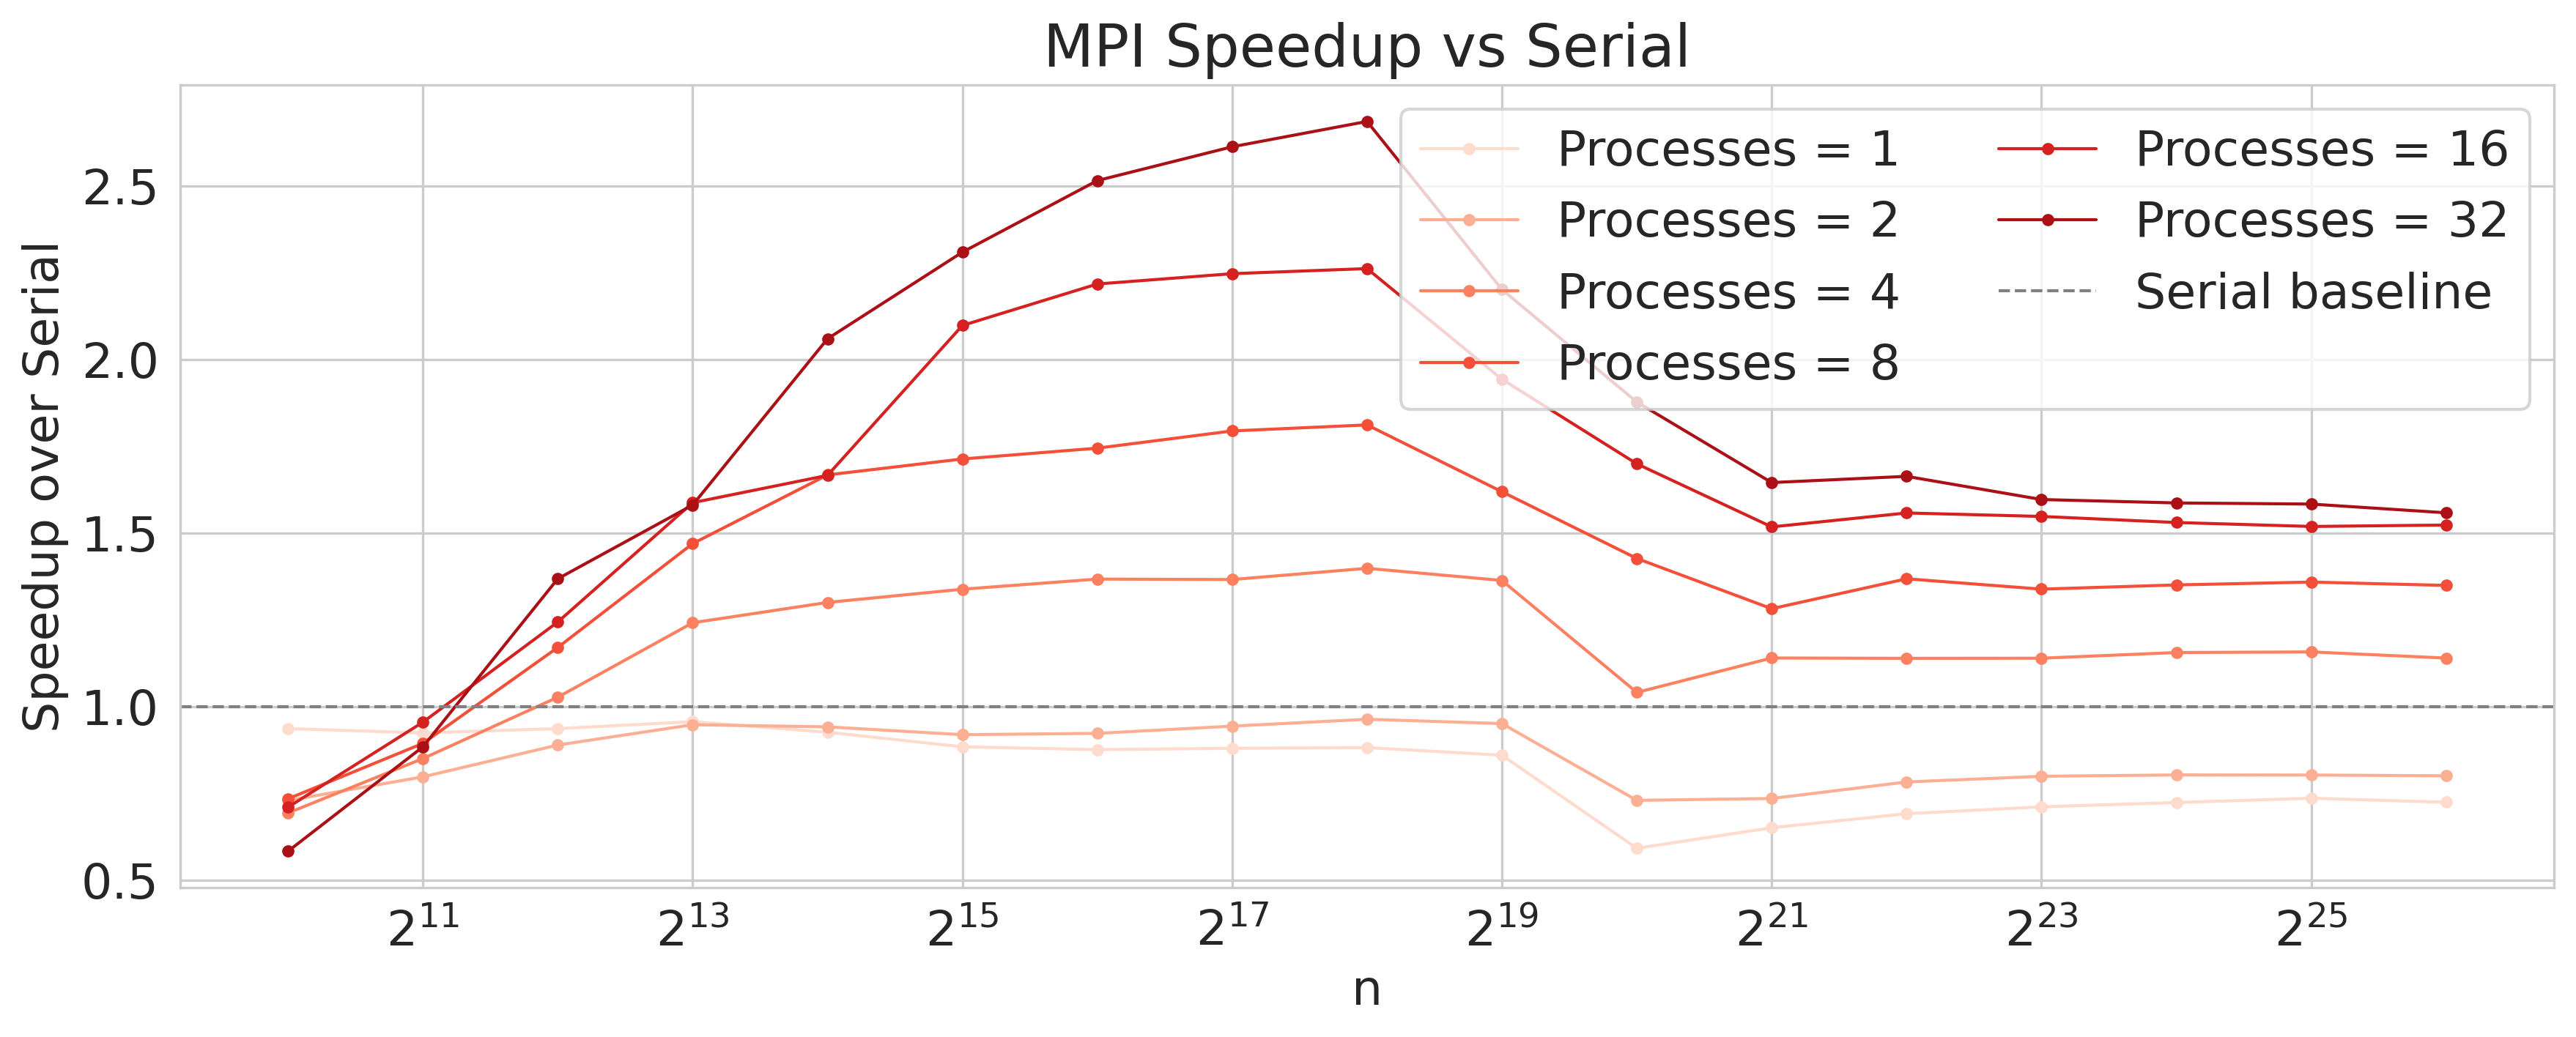

In [54]:
mpi_merged = mpi_df.merge(serial_df, on="n", suffixes=("_mpi", "_serial"))
mpi_merged["speedup"] = mpi_merged["time_ms_serial"] / mpi_merged["time_ms_mpi"]

proc_counts = sorted(mpi_df["processes"].unique())
for i, p in enumerate(proc_counts):
    subset = mpi_merged[mpi_merged["processes"] == p]
    plt.plot(subset["n"], subset["speedup"], marker='o', markersize=3, color=mpi_col[i], label=f"Processes = {p}")

plt.axhline(y=1, linestyle='--', color='gray', label='Serial baseline')
plt.xscale("log", base=2)
plt.xlabel("n")
plt.ylabel("Speedup over Serial")
plt.title("MPI Speedup vs Serial")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig("plots/mpi_speedup.svg")
plt.show()

# CUDA

## Speedup vs Serial (by block size)

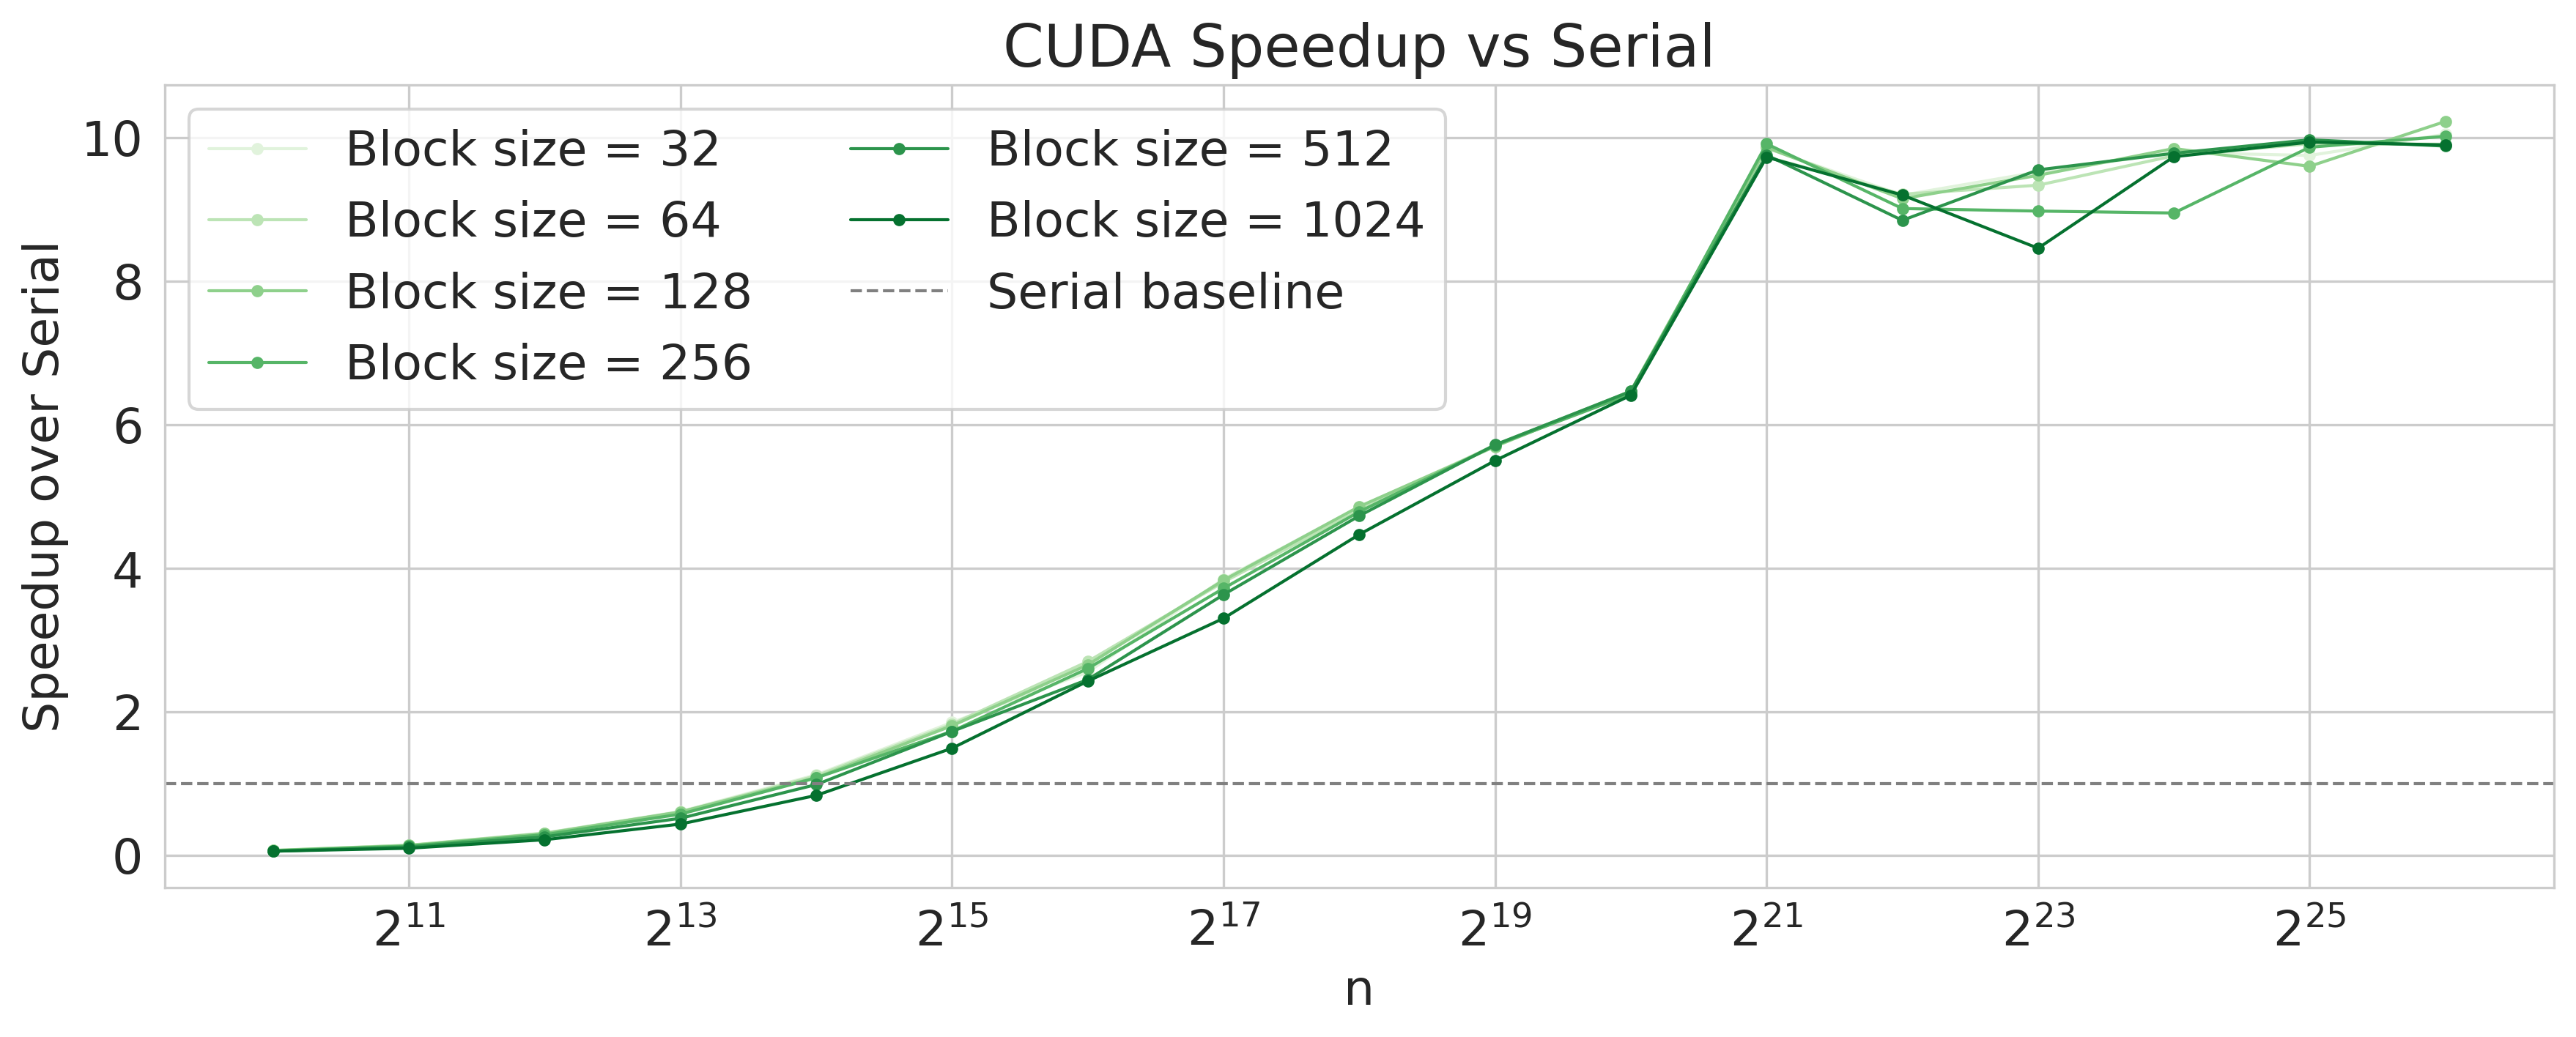

In [55]:
cuda_merged = cuda_df.merge(serial_df, on="n", suffixes=("_cuda", "_serial"))
cuda_merged["speedup"] = cuda_merged["time_ms_serial"] / cuda_merged["time_ms_cuda"]

block_sizes = sorted(cuda_df["block_size"].unique())
for i, bs in enumerate(block_sizes):
    subset = cuda_merged[cuda_merged["block_size"] == bs]
    plt.plot(subset["n"], subset["speedup"], marker='o', markersize=3, color=cuda_col[i], label=f"Block size = {bs}")

plt.axhline(y=1, linestyle='--', color='gray', label='Serial baseline')
plt.xscale("log", base=2)
plt.xlabel("n")
plt.ylabel("Speedup over Serial")
plt.title("CUDA Speedup vs Serial")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig("plots/cuda_speedup.svg")
plt.show()

# JAX

## Speedup vs Serial

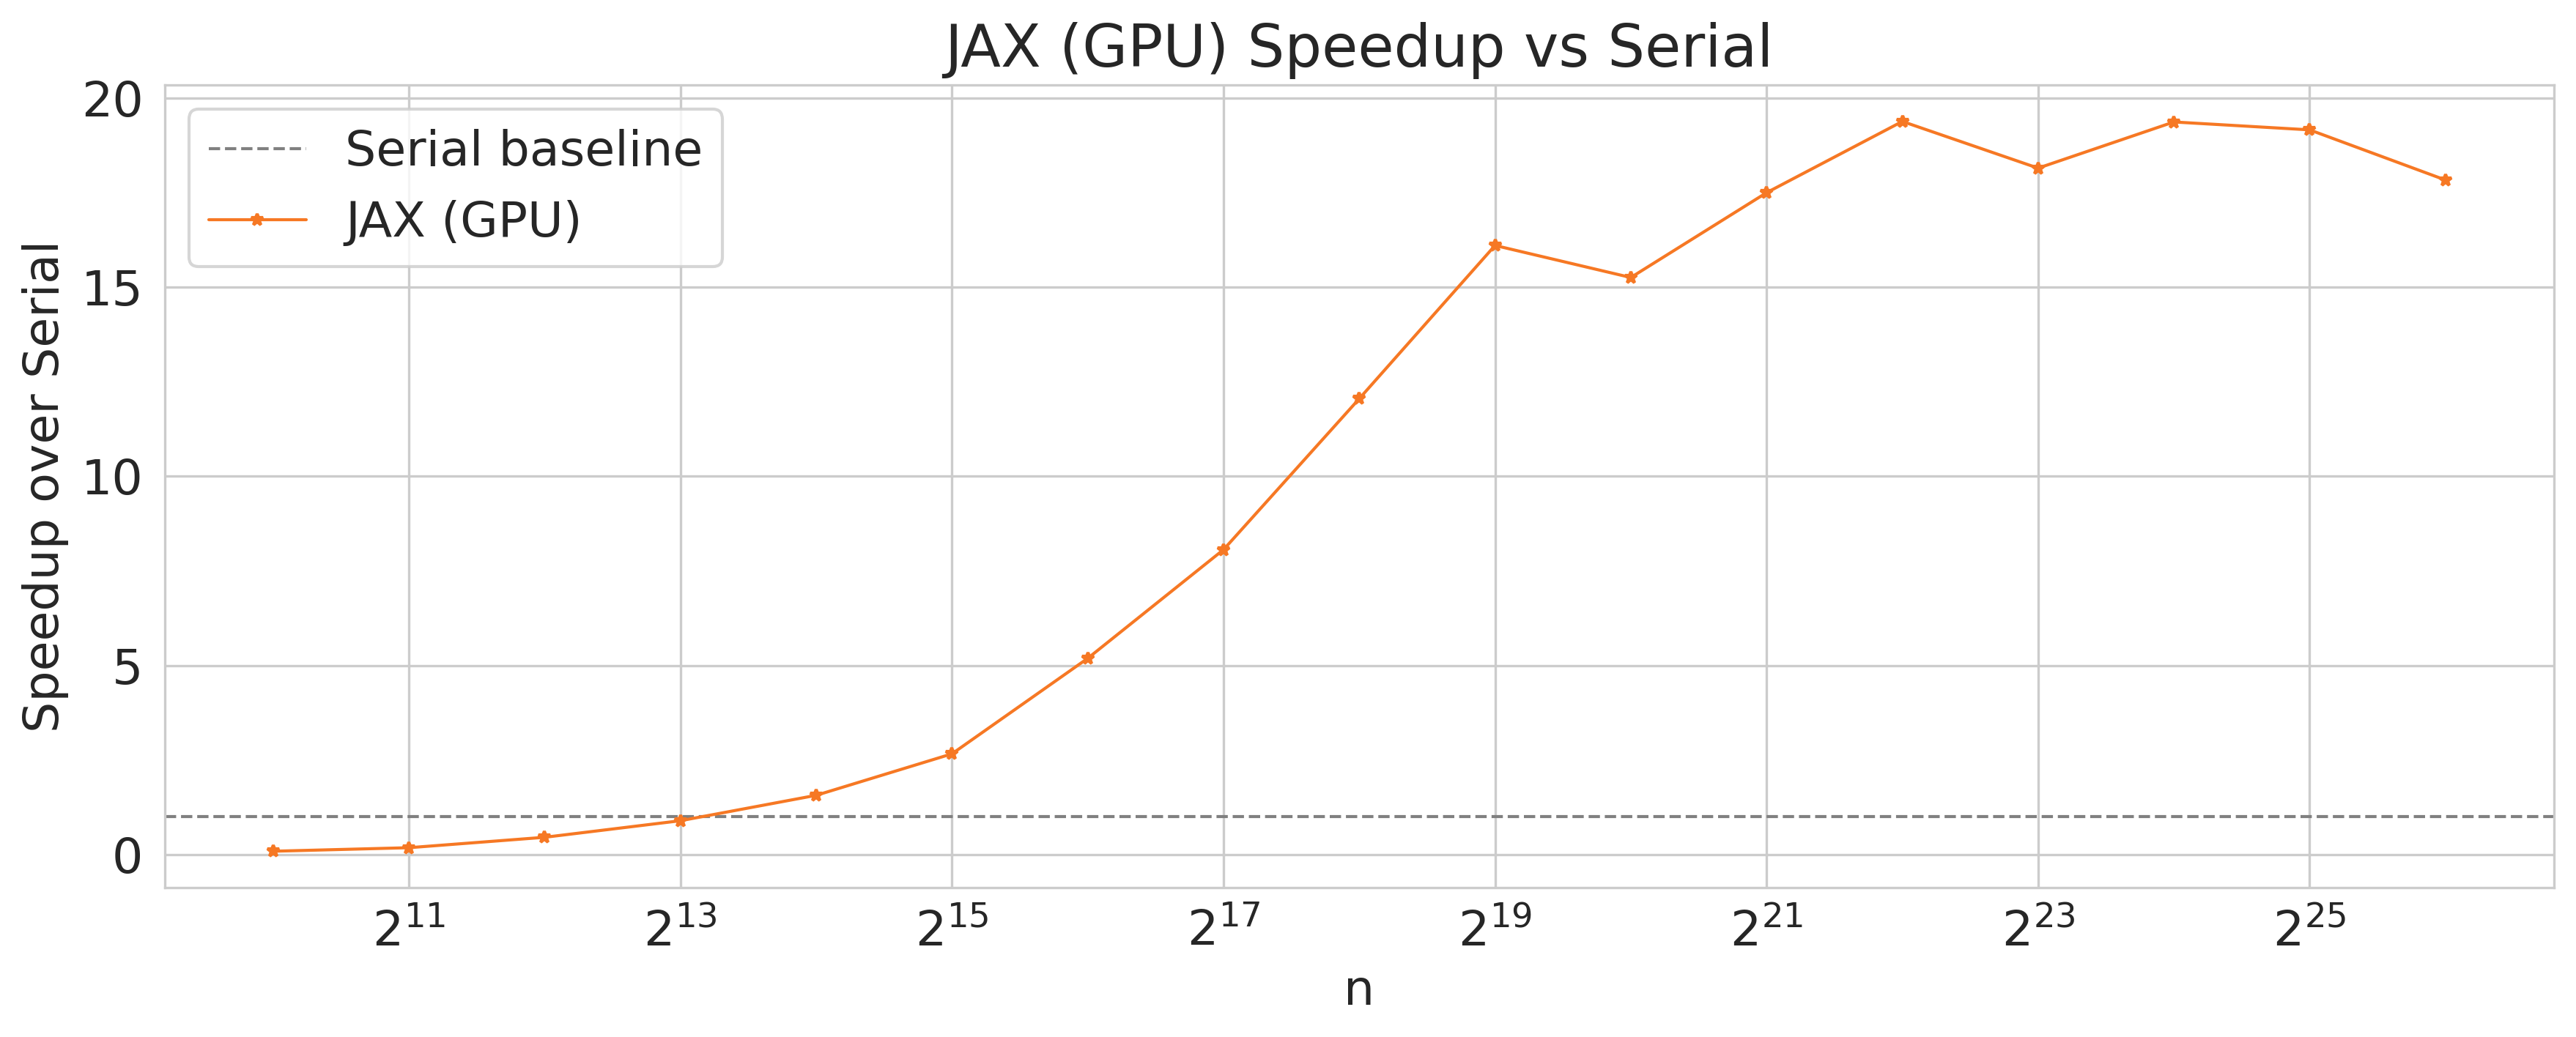

In [57]:
jax_merged = addn_df.merge(serial_df, on="n", suffixes=("_jax", "_serial"))
jax_merged["speedup"] = jax_merged["time_ms_serial"] / jax_merged["time_ms_jax"]

plt.axhline(y=1, linestyle='--', color='gray', label='Serial baseline')
plt.plot(jax_merged["n"], jax_merged["speedup"], marker='*', markersize=4, color=addn_col[3], label="JAX (GPU)")

plt.xscale("log", base=2)
plt.xlabel("n")
plt.ylabel("Speedup over Serial")
plt.title("JAX (GPU) Speedup vs Serial")
plt.legend()
plt.tight_layout()
plt.savefig("plots/jax_speedup.svg")
plt.show()

# Combined Comparison

## Best of each implementation (runtime vs n)

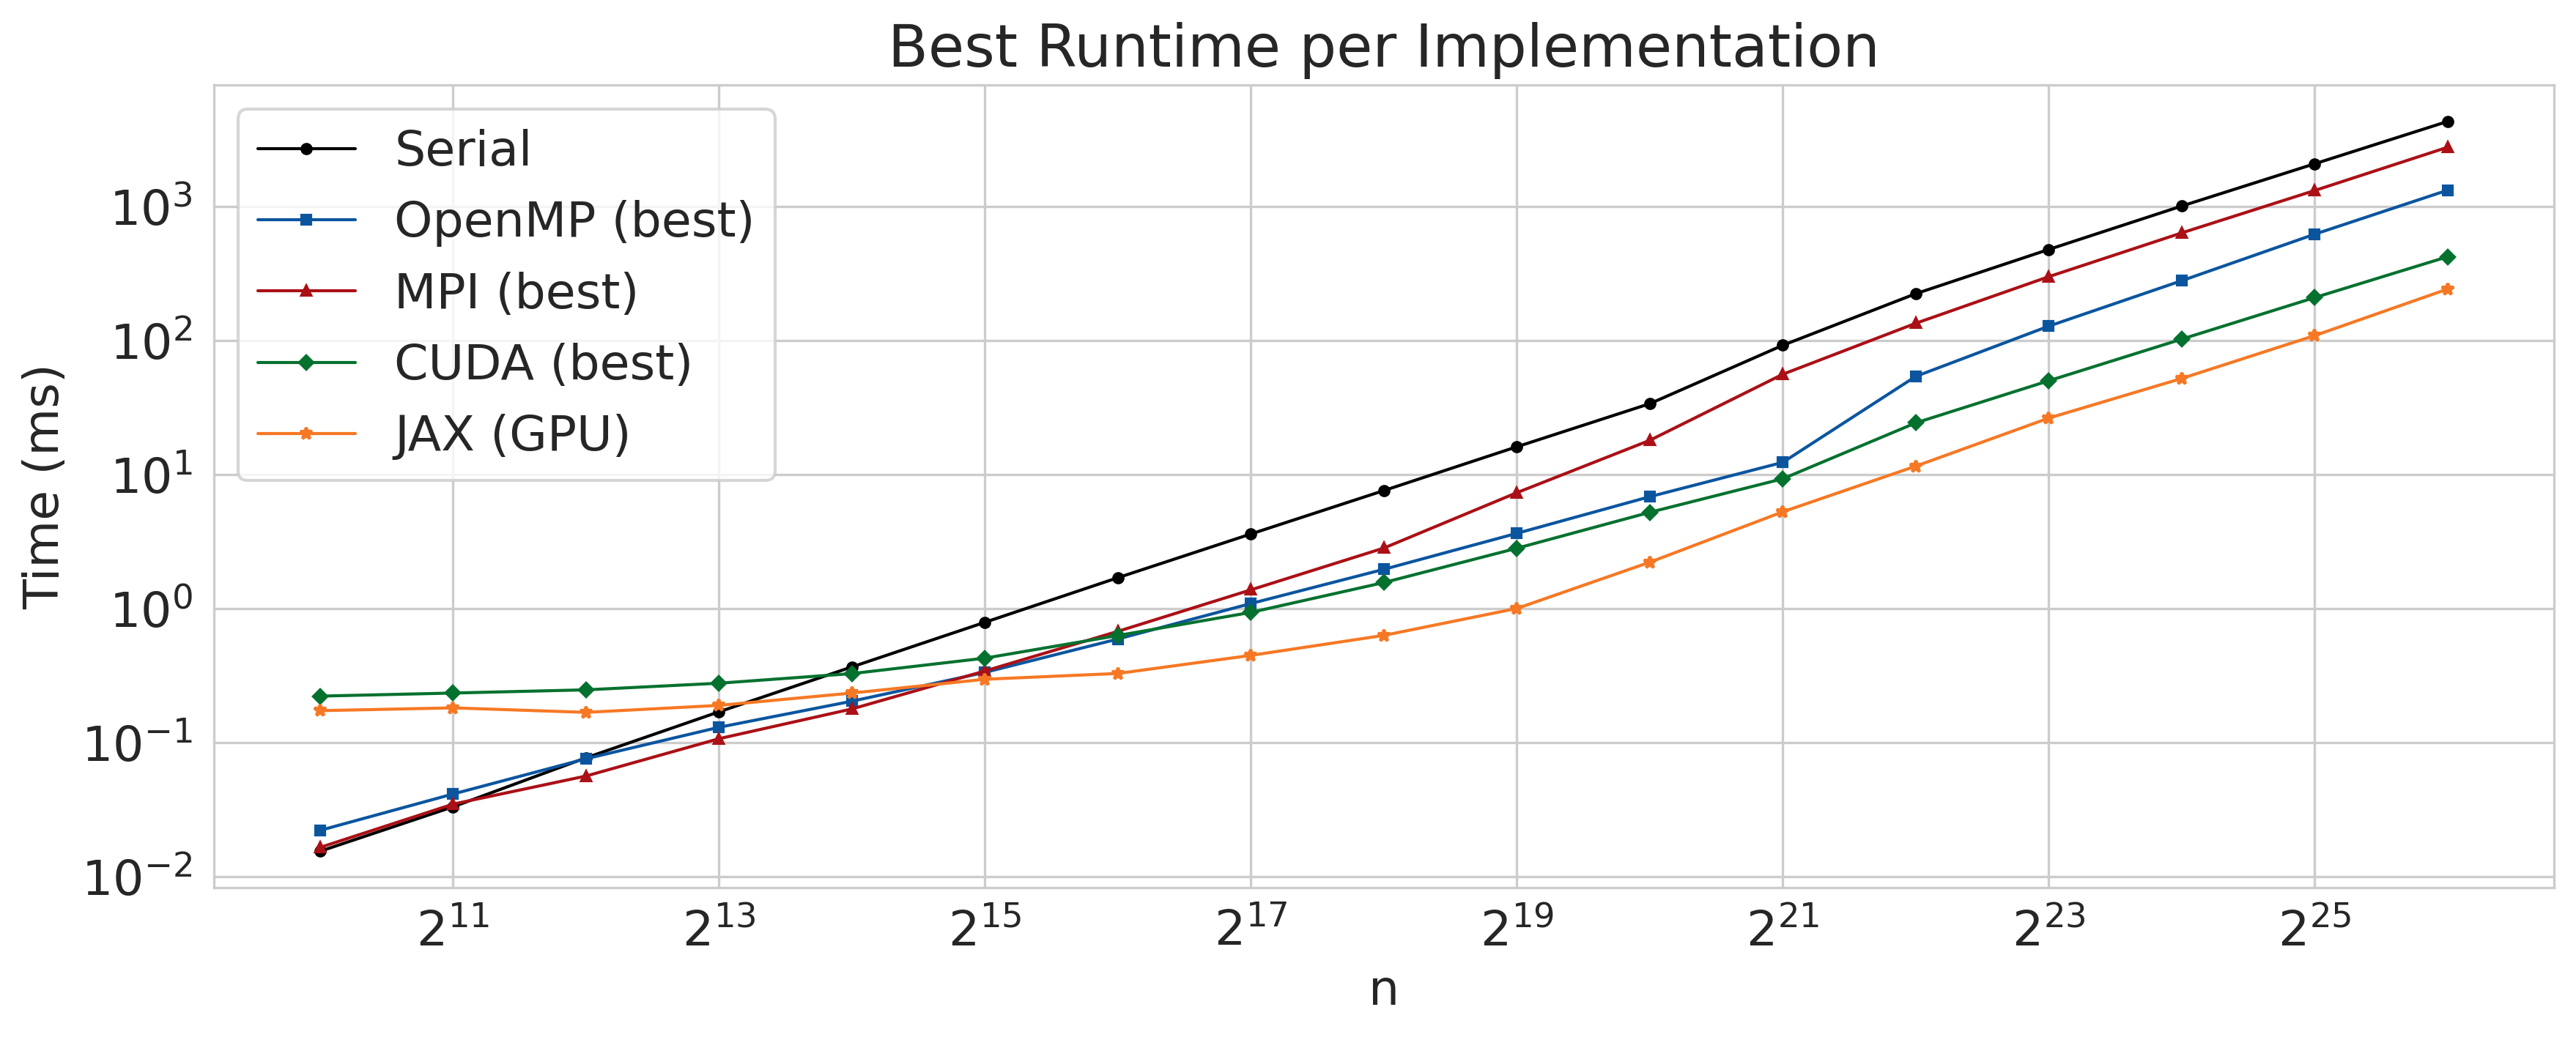

In [58]:
# best config for each implementation
omp_best = omp_df.loc[omp_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)
mpi_best = mpi_df.loc[mpi_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)
cuda_best = cuda_df.loc[cuda_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)

fig, ax = plt.subplots()
ax.plot(serial_df["n"], serial_df["time_ms"], marker='o', markersize=3, color=serial_col, label="Serial")
ax.plot(omp_best["n"], omp_best["time_ms"], marker='s', markersize=3, color=omp_col[-1], label="OpenMP (best)")
ax.plot(mpi_best["n"], mpi_best["time_ms"], marker='^', markersize=3, color=mpi_col[-1], label="MPI (best)")
ax.plot(cuda_best["n"], cuda_best["time_ms"], marker='D', markersize=3, color=cuda_col[-1], label="CUDA (best)")
ax.plot(addn_df["n"], addn_df["time_ms"], marker='*', markersize=4, color=addn_col[3], label="JAX (GPU)")

ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("n")
ax.set_ylabel("Time (ms)")
ax.set_title("Best Runtime per Implementation")
ax.legend()
plt.tight_layout()
plt.savefig("plots/best_runtime.svg")
plt.show()

## Speedup over Serial

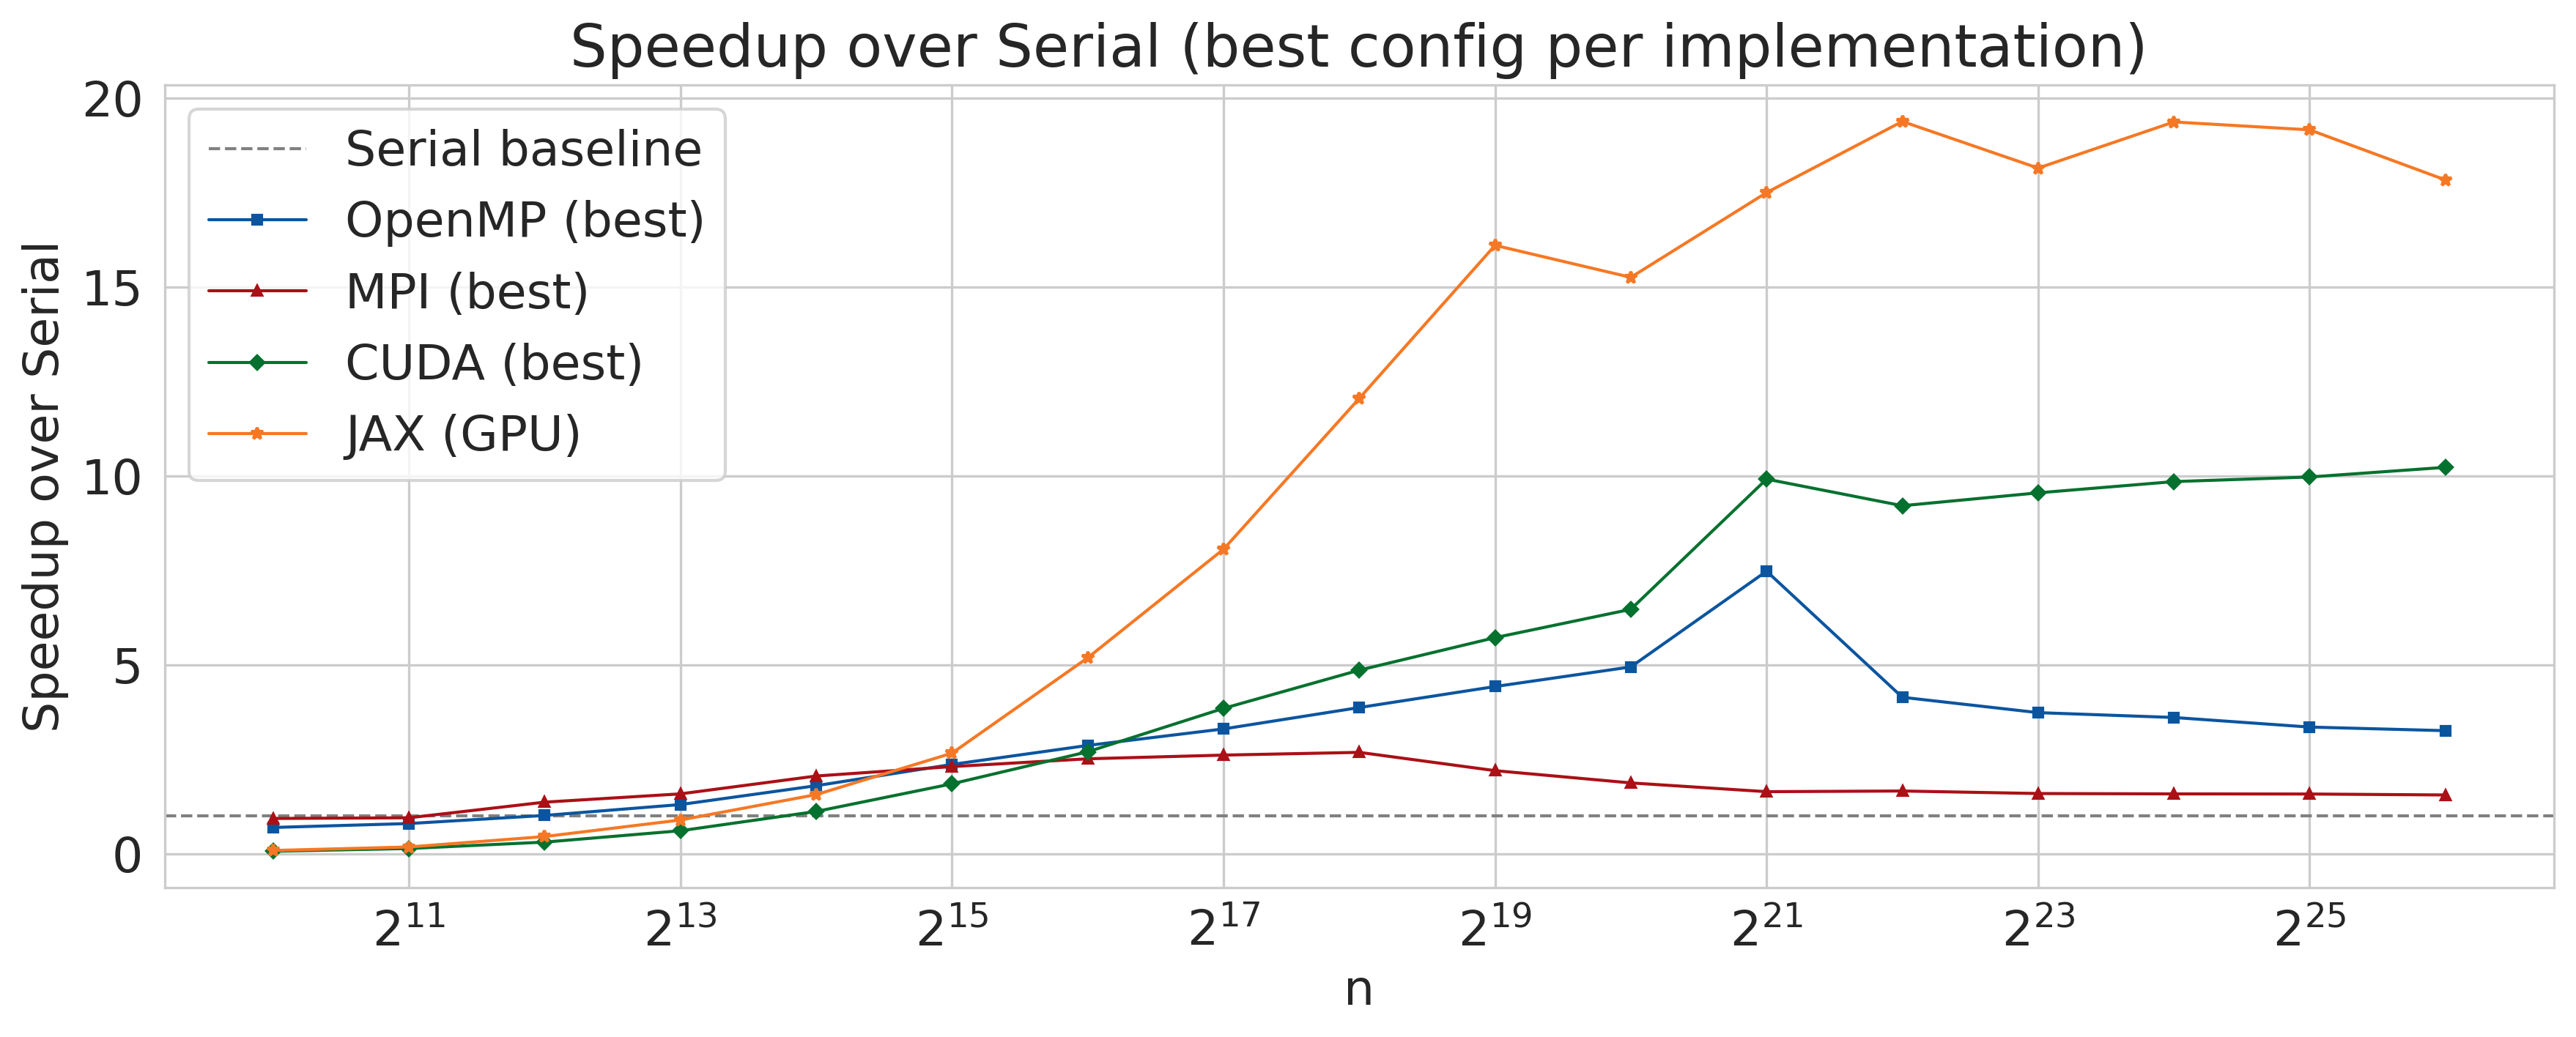

In [59]:
omp_speedup = omp_best.merge(serial_df, on="n", suffixes=("_omp", "_serial"))
mpi_speedup = mpi_best.merge(serial_df, on="n", suffixes=("_mpi", "_serial"))
cuda_speedup = cuda_best.merge(serial_df, on="n", suffixes=("_cuda", "_serial"))
jax_speedup = addn_df.merge(serial_df, on="n", suffixes=("_jax", "_serial"))

fig, ax = plt.subplots()
ax.axhline(y=1, linestyle='--', color='gray', label='Serial baseline')
ax.plot(omp_speedup["n"], omp_speedup["time_ms_serial"] / omp_speedup["time_ms_omp"],
        marker='s', markersize=3, color=omp_col[-1], label="OpenMP (best)")
ax.plot(mpi_speedup["n"], mpi_speedup["time_ms_serial"] / mpi_speedup["time_ms_mpi"],
        marker='^', markersize=3, color=mpi_col[-1], label="MPI (best)")
ax.plot(cuda_speedup["n"], cuda_speedup["time_ms_serial"] / cuda_speedup["time_ms_cuda"],
        marker='D', markersize=3, color=cuda_col[-1], label="CUDA (best)")
ax.plot(jax_speedup["n"], jax_speedup["time_ms_serial"] / jax_speedup["time_ms_jax"],
        marker='*', markersize=4, color=addn_col[3], label="JAX (GPU)")

ax.set_xscale("log", base=2)
ax.set_xlabel("n")
ax.set_ylabel("Speedup over Serial")
ax.set_title("Speedup over Serial (best config per implementation)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/best_speedup.svg")
plt.show()